### Cell 1: load the data

In [19]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

data = pd.read_csv("../data/processed/model_table.csv")
print(data.shape)
data.head()

(45, 10)


,Country Code,country,IncomeGroup,life_expectancy,health_spending_pct_gdp,electricity_access,basic_water,basic_sanitation,urban_population_pct,log_gdp_per_capita
0,AGO,Angola,Lower middle income,63.051,2.203943,45.6,64.159911,49.547024,66.663782,7.827188
1,BDI,Burundi,Low income,62.180,9.059406,9.8,63.757991,44.357739,18.786178,5.456648
2,BEN,Benin,Lower middle income,59.888,3.002069,40.0,67.983252,18.842084,48.712550,7.030700
3,BFA,Burkina Faso,Low income,60.184,5.350011,17.6,50.699617,26.718569,26.118725,6.639684
4,BWA,Botswana,Upper middle income,67.167,6.121932,70.1,91.474948,69.815060,66.327169,8.877952


### Cell 2: the simplest model, one predictor

In [20]:
y = data["life_expectancy"]
X = sm.add_constant(data[["log_gdp_per_capita"]])

simple = sm.OLS(y, X).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:        life_expectancy   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.205
Method:                 Least Squares   F-statistic:                     12.32
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00107
Time:                        10:46:14   Log-Likelihood:                -143.16
No. Observations:                  45   AIC:                             290.3
Df Residuals:                      43   BIC:                             293.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 38.3753      6

### Cell 3: the multiple regression with all six predictors

In [21]:
features = ["log_gdp_per_capita", "health_spending_pct_gdp", "electricity_access",
            "basic_water", "basic_sanitation", "urban_population_pct"]

X = sm.add_constant(data[features])
multi = sm.OLS(y, X).fit()
print(multi.summary())

                            OLS Regression Results                            
Dep. Variable:        life_expectancy   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.373
Method:                 Least Squares   F-statistic:                     5.369
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           0.000427
Time:                        10:46:14   Log-Likelihood:                -135.02
No. Observations:                  45   AIC:                             284.0
Df Residuals:                      38   BIC:                             296.7
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

### Cell 4: a side-by-side comparison

In [22]:
comparison = pd.DataFrame({
    "coefficient": multi.params,
    "p_value": multi.pvalues,
})
comparison.round(3)

,coefficient,p_value
const,57.044,0.000
log_gdp_per_capita,-0.862,0.596
health_spending_pct_gdp,-0.569,0.044
electricity_access,0.058,0.375
basic_water,0.161,0.134
basic_sanitation,0.095,0.126
urban_population_pct,-0.071,0.257


### Cell 5: VIF, which measures predictor overlap

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(data[features])
vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
vif[vif["feature"] != "const"].round(2)

,feature,VIF
1,log_gdp_per_capita,3.66
2,health_spending_pct_gdp,1.19
3,electricity_access,4.16
4,basic_water,3.88
5,basic_sanitation,2.71
6,urban_population_pct,1.65


### Cell 6: which countries have the most influence?

In [24]:
data["cooks_d"] = multi.get_influence().cooks_distance[0]
print("Threshold (4/n):", round(4 / len(data), 3))
data.sort_values("cooks_d", ascending=False)[["country", "life_expectancy", "cooks_d"]].head(5)

Threshold (4/n): 0.089


,country,life_expectancy,cooks_d
5,Central African Republic,31.530,0.727974
12,Ethiopia,65.741,0.072022
22,Mali,59.217,0.055799
29,Nigeria,53.009,0.050832
36,Eswatini,59.850,0.050709


### Cell 7: refit with and without the outliers

In [25]:
def fit(df, cols):
    X = sm.add_constant(df[cols])
    return sm.OLS(df["life_expectancy"], X).fit()

no_caf = data[data["Country Code"] != "CAF"]
no_caf_lso = no_caf[no_caf["Country Code"] != "LSO"]

models = {"all_45": data, "no_CAF": no_caf, "no_CAF_LSO": no_caf_lso}

print("Simple model (log GDP only):")
for name, df in models.items():
    m = fit(df, ["log_gdp_per_capita"])
    print(f"  {name}: slope={m.params['log_gdp_per_capita']:.2f}, R2={m.rsquared:.3f}, n={len(df)}")

print("\nSix-predictor model:")
table = pd.DataFrame({name: fit(df, features).params for name, df in models.items()})
r2 = {name: round(fit(df, features).rsquared_adj, 3) for name, df in models.items()}
print("Adjusted R2:", r2)
table.round(3)

Simple model (log GDP only):
  all_45: slope=3.33, R2=0.223, n=45
  no_CAF: slope=2.49, R2=0.240, n=44
  no_CAF_LSO: slope=2.43, R2=0.245, n=43

Six-predictor model:
Adjusted R2: {'all_45': np.float64(0.373), 'no_CAF': np.float64(0.407), 'no_CAF_LSO': np.float64(0.4)}


,all_45,no_CAF,no_CAF_LSO
const,57.044,61.692,60.666
log_gdp_per_capita,-0.862,-0.540,-0.577
health_spending_pct_gdp,-0.569,-0.292,0.132
electricity_access,0.058,0.062,0.078
basic_water,0.161,-0.010,-0.035
basic_sanitation,0.095,0.119,0.110
urban_population_pct,-0.071,-0.006,0.009


### Cell 8: coefficients with p-values and intervals, without CAR

In [26]:
m = fit(no_caf, features)
pd.DataFrame({
    "coef": m.params,
    "p_value": m.pvalues,
    "ci_low": m.conf_int()[0],
    "ci_high": m.conf_int()[1],
}).round(3)

,coef,p_value,ci_low,ci_high
const,61.692,0.000,48.972,74.413
log_gdp_per_capita,-0.540,0.633,-2.811,1.730
health_spending_pct_gdp,-0.292,0.140,-0.686,0.101
electricity_access,0.062,0.182,-0.030,0.153
basic_water,-0.010,0.902,-0.167,0.148
basic_sanitation,0.119,0.008,0.033,0.205
urban_population_pct,-0.006,0.900,-0.095,0.084


### Cell 9: residual plots for that model

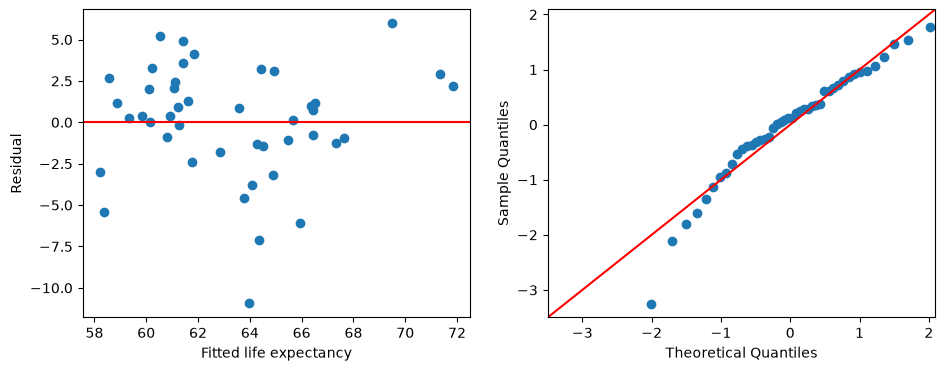

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(m.fittedvalues, m.resid)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("Fitted life expectancy")
ax[0].set_ylabel("Residual")
sm.qqplot(m.resid, line="45", fit=True, ax=ax[1])
plt.show()

### Cell 10: honest comparison with cross-validation

In [28]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_no = no_caf["life_expectancy"]
small = ["log_gdp_per_capita", "electricity_access", "basic_sanitation"]

def cv_scores(model, X):
    r2 = cross_val_score(model, X, y_no, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X, y_no, cv=cv, scoring="neg_root_mean_squared_error")
    return round(r2.mean(), 3), round(rmse.mean(), 2)

results = {
    "Mean-only baseline": cv_scores(DummyRegressor(), no_caf[features]),
    "OLS, log GDP only": cv_scores(LinearRegression(), no_caf[["log_gdp_per_capita"]]),
    "OLS, 3 predictors": cv_scores(make_pipeline(StandardScaler(), LinearRegression()), no_caf[small]),
    "OLS, 6 predictors": cv_scores(make_pipeline(StandardScaler(), LinearRegression()), no_caf[features]),
    "Ridge, 6 predictors": cv_scores(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 50))), no_caf[features]),
    "Lasso, 6 predictors": cv_scores(make_pipeline(StandardScaler(), LassoCV(cv=5)), no_caf[features]),
}
pd.DataFrame(results, index=["CV R2", "CV RMSE"]).T

,CV R2,CV RMSE
Mean-only baseline,-0.509,4.66
"OLS, log GDP only",-0.689,4.42
"OLS, 3 predictors",-0.195,3.85
"OLS, 6 predictors",-0.569,4.29
"Ridge, 6 predictors",-0.394,4.21
"Lasso, 6 predictors",-0.249,3.89


### Cell 11: which countries have the biggest misses?

In [29]:
res = no_caf.assign(fitted=m.fittedvalues, residual=m.resid)
cols = ["country", "life_expectancy", "fitted", "residual"]
res.sort_values("residual")[cols].iloc[[0, 1, 2, -3, -2, -1]].round(2)

,country,life_expectancy,fitted,residual
29,Nigeria,53.01,63.95,-10.94
34,"Somalia, Fed. Rep.",57.25,64.37,-7.12
36,Eswatini,59.85,65.94,-6.09
41,Uganda,66.35,61.43,4.92
12,Ethiopia,65.74,60.54,5.20
11,Cabo Verde,75.45,69.48,5.97


### Cell 12: a steadier comparison with repeated cross-validation

In [30]:
from sklearn.model_selection import RepeatedKFold

rcv = RepeatedKFold(n_splits=5, n_repeats=20, random_state=42)

def cv_rmse(model, X):
    scores = -cross_val_score(model, X, y_no, cv=rcv, scoring="neg_root_mean_squared_error")
    return round(scores.mean(), 2), round(scores.std(), 2)

ols = lambda: make_pipeline(StandardScaler(), LinearRegression())
results2 = {
    "Baseline (mean only)": cv_rmse(DummyRegressor(), no_caf[features]),
    "log GDP only": cv_rmse(ols(), no_caf[["log_gdp_per_capita"]]),
    "Sanitation only": cv_rmse(ols(), no_caf[["basic_sanitation"]]),
    "Electricity + sanitation": cv_rmse(ols(), no_caf[["electricity_access", "basic_sanitation"]]),
    "log GDP + electricity + sanitation": cv_rmse(ols(), no_caf[small]),
    "All 6 (OLS)": cv_rmse(ols(), no_caf[features]),
    "All 6 (Lasso)": cv_rmse(make_pipeline(StandardScaler(), LassoCV(cv=5)), no_caf[features]),
}
pd.DataFrame(results2, index=["mean RMSE", "std across folds"]).T

,mean RMSE,std across folds
Baseline (mean only),4.68,1.27
log GDP only,4.22,1.05
Sanitation only,3.73,0.98
Electricity + sanitation,3.62,0.95
log GDP + electricity + sanitation,3.71,0.94
All 6 (OLS),4.19,1.14
All 6 (Lasso),3.80,1.09


### Cell 13: the Kenya question, with an honest range

In [31]:
train = no_caf[no_caf["Country Code"] != "KEN"]
kenya = no_caf[no_caf["Country Code"] == "KEN"]

m3 = fit(train, small)
Xk = sm.add_constant(kenya[small], has_constant="add")
frame = m3.get_prediction(Xk).summary_frame(alpha=0.05)

print("Kenya actual 2019:", round(kenya["life_expectancy"].iloc[0], 1))
print("Predicted:", round(frame["mean"].iloc[0], 1))
print("95% prediction range:", round(frame["obs_ci_lower"].iloc[0], 1), "to", round(frame["obs_ci_upper"].iloc[0], 1))

Kenya actual 2019: 62.9
Predicted: 64.1
95% prediction range: 56.4 to 71.9


### Cell 14: the final model, with and without CAR

In [32]:
final_cols = ["electricity_access", "basic_sanitation"]

with_caf = fit(data, final_cols)
without_caf = fit(no_caf, final_cols)

pd.DataFrame({
    "coef_no_CAR": without_caf.params,
    "ci_low": without_caf.conf_int()[0],
    "ci_high": without_caf.conf_int()[1],
    "p_value": without_caf.pvalues,
    "coef_with_CAR": with_caf.params,
}).round(3)

,coef_no_CAR,ci_low,ci_high,p_value,coef_with_CAR
const,56.494,53.830,59.159,0.000,54.004
electricity_access,0.056,-0.008,0.120,0.086,0.086
basic_sanitation,0.097,0.023,0.170,0.011,0.106


In [33]:
print("R2 without CAR:", round(without_caf.rsquared, 3), "| adj:", round(without_caf.rsquared_adj, 3))
print("Correlation between the two predictors:", round(no_caf[final_cols].corr().iloc[0, 1], 2))

R2 without CAR: 0.448 | adj: 0.421
Correlation between the two predictors: 0.7


### Cell 15: honest leave-one-out predictions and the final chart

Leave-one-out RMSE: 3.72


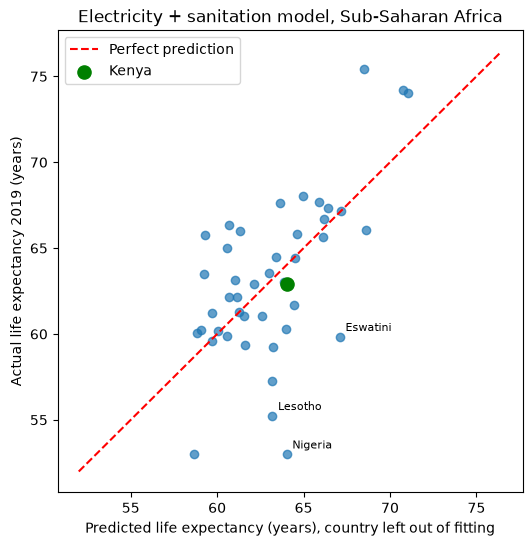

In [34]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import matplotlib.pyplot as plt

pred = cross_val_predict(LinearRegression(), no_caf[final_cols], y_no, cv=LeaveOneOut())
loo = no_caf.assign(predicted=pred, error=y_no - pred)
print("Leave-one-out RMSE:", round(np.sqrt((loo["error"] ** 2).mean()), 2))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(loo["predicted"], loo["life_expectancy"], alpha=0.7)
lims = [loo[["predicted", "life_expectancy"]].min().min() - 1,
        loo[["predicted", "life_expectancy"]].max().max() + 1]
ax.plot(lims, lims, "r--", label="Perfect prediction")

kenya_row = loo[loo["Country Code"] == "KEN"]
ax.scatter(kenya_row["predicted"], kenya_row["life_expectancy"], color="green", s=90, label="Kenya")

worst = loo.reindex(loo["error"].abs().sort_values(ascending=False).index).head(3)
for _, r in worst.iterrows():
    ax.annotate(r["country"], (r["predicted"], r["life_expectancy"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")

ax.set_xlabel("Predicted life expectancy (years), country left out of fitting")
ax.set_ylabel("Actual life expectancy 2019 (years)")
ax.set_title("Electricity + sanitation model, Sub-Saharan Africa")
ax.legend()
fig.savefig("../reports/figures/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
final = fit(no_caf[no_caf["Country Code"] != "KEN"], final_cols)
kenya = no_caf[no_caf["Country Code"] == "KEN"]
Xk = sm.add_constant(kenya[final_cols], has_constant="add")
f = final.get_prediction(Xk).summary_frame(alpha=0.05)

actual = kenya["life_expectancy"].iloc[0]
kenya_pred = f["mean"].iloc[0]
lo, hi = f["obs_ci_lower"].iloc[0], f["obs_ci_upper"].iloc[0]
print(f"Kenya's 2019 life expectancy was {actual:.1f} years; the model predicted {kenya_pred:.1f} (95% prediction range {lo:.1f} to {hi:.1f}).")

Kenya's 2019 life expectancy was 62.9 years; the model predicted 64.1 (95% prediction range 56.4 to 71.7).
